# Notebook 3 — Part 1 results: is it quantum, is it noise, or is it the clock?

**What this notebook covers**

1. The experiment in one paragraph
2. How the scoring works
3. The headline result
4. The same result for every model and every blinding
5. Three questions, answered one at a time
6. The drift check ("the clock")
7. Robustness checks
8. How this compares with HSBC's numbers
9. What we can and cannot conclude

Every number here is computed from the saved predictions of `scripts/04_run_part1.py`. The commentary describes the run stored in this notebook.

In [1]:
# Set-up: make the project's code importable and keep the output tidy.
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", 60); pd.set_option("display.float_format", lambda v: f"{v:.4f}")
%matplotlib inline

## 1. The experiment in one paragraph

We took 16,000 replayed quote requests on real US corporate bonds (Notebook 1) and described each of them in several competing ways (Notebook 2): with the classical inputs (**A**), with the outputs of a 109-qubit circuit on a perfect quantum computer (**B**), with the same circuit on a noisy simulated chip (**C**), with a purely classical imitation of that noise (**E**), and with random classical features (**F**). The same four ordinary models were trained on each description. Whichever description lets the models predict fills best, wins.

## 2. How the scoring works

* **Backtest.** For each of the 68 test days: train on the 4,000 most recent earlier requests, predict that day's requests, move on a day. A model never sees a request from the day it is tested on, or later.
* **Blinding.** Extra days left out between training and testing: 0, 1 or 4. (HSBC's gain was largest at their shortest blinding.)
* **AUC.** The score. 0.5 is guessing; 1.0 is perfect. It is computed for each test day and averaged.
* **Confidence interval.** The range in which a number would plausibly fall on a different draw of days. **A difference only counts if its 95% interval excludes zero.**
* **"All".** The average over the four models (logistic regression, random forest, gradient boosting, neural network).

In [2]:
from qon.analysis import (load, part1_matrix, part1_table, paired_difference, fig_part1_headline,
                          fig_part1_differences, fig_drift)
pred = load("part1_predictions")
print(f"{len(pred):,} saved predictions: {pred['set'].nunique()} feature sets x 4 models x "
      f"{pred['day'].nunique()} test days")

1,280,000 saved predictions: 8 feature sets x 4 models x 68 test days


## 3. The headline result

Blinding 0 (train on everything up to yesterday), averaged over the four models.

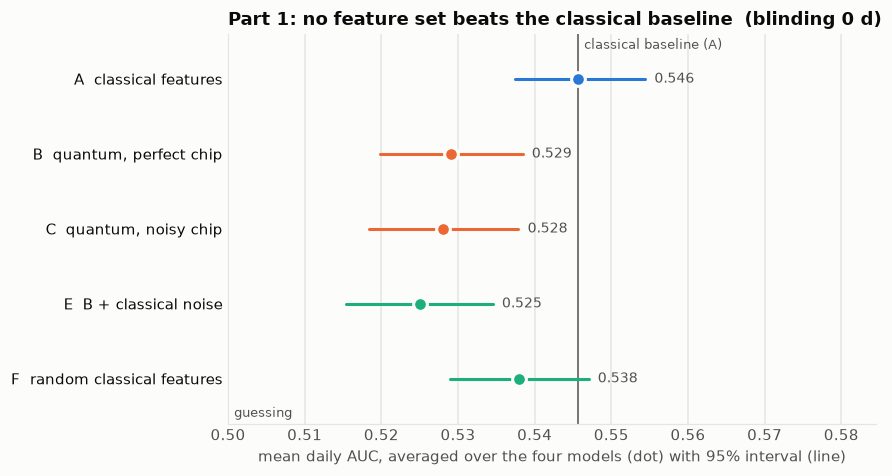

In [3]:
fig_part1_headline(pred, blinding=0);

In [4]:
t = part1_table(pred, 0, "All")
show = t[["mean_auc", "ci_low", "ci_high", "diff_vs_A", "diff_ci_low", "diff_ci_high", "relative_gain_%", "significant"]]
show.columns = ["mean daily AUC", "95% low", "95% high", "difference to A", "diff 95% low", "diff 95% high",
                "relative change (%)", "difference is real?"]
show.round(4)

,mean daily AUC,95% low,95% high,difference to A,diff 95% low,diff 95% high,relative change (%),difference is real?
name,,,,,,,,
A,0.5457,0.5374,0.5544,0.0000,0.0000,0.0000,0.0000,False
B,0.5291,0.5198,0.5384,-0.0165,-0.0232,-0.0097,-3.0328,True
C,0.5281,0.5183,0.5379,-0.0176,-0.0234,-0.0115,-3.2174,True
E,0.5251,0.5153,0.5345,-0.0206,-0.0273,-0.0139,-3.7721,True
F,0.5379,0.5289,0.5470,-0.0077,-0.0134,-0.0024,-1.4142,True


**How to read it**

* The classical inputs (**A**) score an AUC of about **0.546**. That is a weak but real signal (the whole interval is above 0.5), as expected from Notebook 1.
* Both quantum sets (**B** perfect, **C** noisy) score about **0.529**: lower than A by 0.017–0.018, and the interval of the difference is entirely below zero. **The quantum transformation made the predictions worse, not better.**
* The classical imitation of the noise (**E**) lands in the same place as the quantum sets.
* Random classical features (**F**) are also slightly worse than A, but better than the quantum sets.

In HSBC's units ("relative change in AUC"), the quantum sets are about **3% below** the classical baseline, where HSBC report **34% above** for real hardware.

## 4. The same result for every model and every blinding

One table per blinding. Each cell is the mean daily AUC, with the difference to set A in brackets; a star means the difference is statistically real.

In [5]:
for b in (0, 1, 4):
    display(part1_matrix(pred, b))

,All,LR,RF,XGB,NN
blinding = 0 day(s),,,,,
A classical features,0.546,0.546,0.553,0.546,0.537
"B quantum, perfect chip",0.529 (-0.017*),0.529 (-0.017*),0.534 (-0.019*),0.527 (-0.020*),0.527 (-0.011)
"C quantum, noisy chip",0.528 (-0.018*),0.529 (-0.017*),0.537 (-0.016*),0.523 (-0.023*),0.523 (-0.015*)
E B + classical noise,0.525 (-0.021*),0.530 (-0.016*),0.530 (-0.023*),0.521 (-0.025*),0.519 (-0.018*)
F random classical features,0.538 (-0.008*),0.542 (-0.004),0.541 (-0.012*),0.531 (-0.015*),0.538 (+0.000)


,All,LR,RF,XGB,NN
blinding = 1 day(s),,,,,
A classical features,0.544,0.545,0.551,0.550,0.530
"B quantum, perfect chip",0.523 (-0.021*),0.523 (-0.022*),0.524 (-0.028*),0.524 (-0.025*),0.520 (-0.010)
"C quantum, noisy chip",0.518 (-0.026*),0.523 (-0.022*),0.522 (-0.029*),0.511 (-0.039*),0.515 (-0.015*)
E B + classical noise,0.522 (-0.023*),0.524 (-0.021*),0.531 (-0.021*),0.516 (-0.034*),0.516 (-0.014*)
F random classical features,0.535 (-0.009*),0.542 (-0.003),0.538 (-0.013*),0.527 (-0.023*),0.531 (+0.001)


,All,LR,RF,XGB,NN
blinding = 4 day(s),,,,,
A classical features,0.541,0.544,0.550,0.547,0.524
"B quantum, perfect chip",0.522 (-0.020*),0.529 (-0.016*),0.523 (-0.028*),0.515 (-0.032*),0.521 (-0.003)
"C quantum, noisy chip",0.521 (-0.020*),0.529 (-0.016*),0.530 (-0.020*),0.511 (-0.035*),0.514 (-0.010)
E B + classical noise,0.522 (-0.019*),0.528 (-0.016*),0.525 (-0.025*),0.515 (-0.031*),0.519 (-0.005)
F random classical features,0.532 (-0.009*),0.540 (-0.004),0.532 (-0.018*),0.525 (-0.022*),0.531 (+0.007)


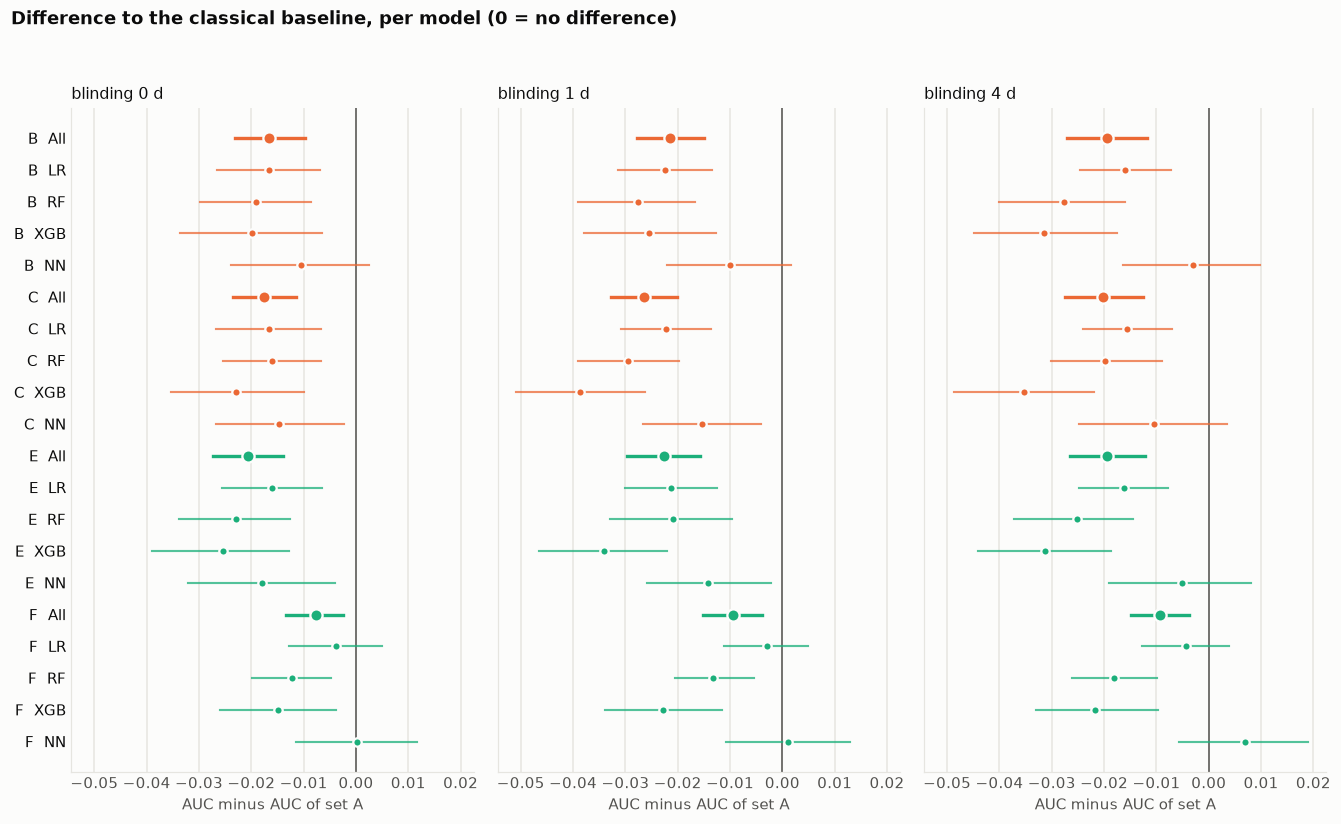

In [6]:
fig_part1_differences(pred);

**How to read the chart.** Each panel is one blinding. Each line is the difference to the classical baseline for one feature set and one model (the thick line is the average over models). Everything to the **left** of the vertical zero line is *worse* than the classical inputs.

The picture is the same everywhere: for every model and every blinding, the quantum sets B and C and the noise imitation E sit to the left of zero. Nothing sits clearly to the right.

## 5. Three questions, answered one at a time

In [7]:
questions = [("B", "A", "Is it QUANTUM?  perfect quantum features vs classical inputs"),
             ("C", "B", "Is it NOISE?  noisy chip vs perfect chip"),
             ("B_shots", "B", "Is it SHOT noise?  perfect chip + finite shots vs perfect chip"),
             ("C", "E", "Is chip noise special?  noisy chip vs classical imitation of its noise"),
             ("F", "A", "Is it MORE FEATURES?  random classical features vs classical inputs"),
             ("B", "F", "Quantum features vs random classical features")]
rows = []
for a, b, text in questions:
    d = paired_difference(pred, a, b, 0)
    rows.append({"question": text, "AUC difference": d["mean_diff"], "95% low": d["ci_low"],
                 "95% high": d["ci_high"], "real difference?": d["significant"]})
pd.DataFrame(rows).set_index("question").round(4)

,AUC difference,95% low,95% high,real difference?
question,,,,
Is it QUANTUM? perfect quantum features vs classical inputs,-0.0165,-0.0232,-0.0097,True
Is it NOISE? noisy chip vs perfect chip,-0.0010,-0.0051,0.0033,False
Is it SHOT noise? perfect chip + finite shots vs perfect chip,0.0004,-0.0036,0.0045,False
Is chip noise special? noisy chip vs classical imitation of its noise,0.0030,-0.0006,0.0069,False
Is it MORE FEATURES? random classical features vs classical inputs,-0.0077,-0.0134,-0.0024,True
Quantum features vs random classical features,-0.0088,-0.0151,-0.0024,True


**Is it quantum?** No. Pushing the data through the circuit on a perfect quantum computer *lowers* the AUC by about 0.017. This agrees with HSBC's own finding that noiseless simulation gave no gain.

Why would it hurt? The circuit is a fixed scrambling of the inputs that knows nothing about fills. Each of its 327 outputs depends on only a handful of the 98 inputs, squashed through sines and cosines. Some information is blurred on the way and nothing new is added.

**Is it noise?** No. The noisy chip scores the same as the perfect chip (difference about −0.001, interval comfortably straddling zero). Shot noise alone also changes nothing. Noise of the kind a quantum chip has (shrinking and random scatter) cannot add information about the market; at best it does no harm.

**Is chip noise special?** No. The classical imitation (E) and the simulated chip (C) are statistically indistinguishable. Whatever the simulated noise does, ordinary random numbers do too.

**Is it just more non-linear features?** Not even that helps here. Random classical features are slightly worse than the raw inputs, though better than the quantum features.

**Bottom line for the simulated part:** on this data we find no route by which the quantum feature map, with or without simulated noise, improves fill prediction.

## 6. The drift check: "is it the clock?"

Notebook 2 showed that when events are sent to a drifting chip in **date order**, the drift becomes a hidden clock: it reveals whether an event is early or late with about 99% accuracy. Sent in **random order**, it does not.

Does that hidden clock make the models *predict better*? We trained the same models on both versions and compare them directly.

,mean_diff,ci_low,ci_high,significant
label,,,,
"alpha = 1.0, blinding 0",0.0000,-0.0046,0.0043,False
"alpha = 1.0, blinding 4",-0.0040,-0.0088,0.0002,False
"alpha = 0.1, blinding 0",0.0013,-0.0040,0.0063,False


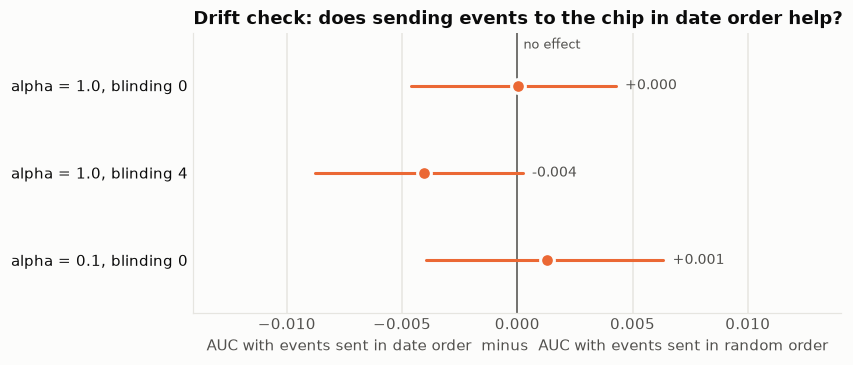

In [8]:
small = load("part1_predictions_alpha0.1")
rows = []
for label, p, b in (("alpha = 1.0, blinding 0", pred, 0), ("alpha = 1.0, blinding 4", pred, 4),
                    ("alpha = 0.1, blinding 0", small, 0)):
    d = paired_difference(p, "C_drift_chrono", "C_drift_random", b)
    rows.append({"label": label, **d})
drift = pd.DataFrame(rows)
fig_drift(drift);
drift[["label", "mean_diff", "ci_low", "ci_high", "significant"]].set_index("label").round(4)

In [9]:
# The same comparison model by model (to show nothing is hiding in the average).
rows = []
for label, p, b in (("alpha 1.0, blinding 0", pred, 0), ("alpha 1.0, blinding 4", pred, 4), ("alpha 0.1, blinding 0", small, 0)):
    for m in ("LR", "RF", "XGB", "NN"):
        d = paired_difference(p, "C_drift_chrono", "C_drift_random", b, m)
        rows.append({"setting": label, "model": m, "date order minus random order": d["mean_diff"],
                     "95% low": d["ci_low"], "95% high": d["ci_high"], "real?": d["significant"]})
pd.DataFrame(rows).set_index(["setting", "model"]).round(4)

date order minus random order  95% low  95% high  real?
setting               model                                                         
alpha 1.0, blinding 0 LR                           -0.0024  -0.0048   -0.0001   True
                      RF                            0.0017  -0.0064    0.0096  False
                      XGB                          -0.0009  -0.0107    0.0081  False
                      NN                            0.0017  -0.0083    0.0108  False
alpha 1.0, blinding 4 LR                            0.0005  -0.0018    0.0030  False
                      RF                           -0.0002  -0.0071    0.0066  False
                      XGB                          -0.0105  -0.0209   -0.0003   True
                      NN                           -0.0060  -0.0168    0.0046  False
alpha 0.1, blinding 0 LR                            0.0008  -0.0038    0.0055  False
                      RF                            0.0074   0.0004    0.0139   True
                      XGB                          -0.0011  -0.0106    0.0082  False
                      NN                           -0.0019  -0.0139    0.0094  False

**Result: the clock exists, but on this data it does not help.** Sending the events in date order makes no measurable difference to the average score in any of the three settings.

In the model-by-model table three of the twelve cells are flagged as "real". Two say date order is slightly *worse* and one says slightly *better*; all three are about 0.01 or less. When twelve comparisons are each tested at the 95% level, a flag or two is expected by chance alone, and there is no consistent direction. We therefore read this as no effect, and report every cell so that you can judge for yourself.

**Why the clock is harmless here, and why that does not clear HSBC.** A clock can only help if (1) fills are easier at some times than others and (2) the model does not already know the date. In our data condition 2 fails: the classical inputs already contain the date in disguise (yesterday's interest rates, VIX and credit spreads are the same for every request on a given day, and different on different days). The hidden clock tells the models nothing new.

We cannot check either condition for HSBC's private data. Their paper reports that the hardware gain shrinks as the blinding grows, which is the pattern a clock would produce, but it does not prove it. What our result does establish is the practical lesson: **if you send time-ordered data to a quantum chip, the output contains the time. Randomise the run order**, as our hardware protocol does.

## 7. Robustness checks

Does the conclusion depend on choices we made? Two checks.

**(a) A training window of HSBC's size.** HSBC trained on 500–2,000 events; we used 4,000. Here is the same experiment with 1,000.

In [10]:
display(part1_matrix(load("part1_predictions_train1000"), 0))

,All,LR,RF,XGB,NN
blinding = 0 day(s),,,,,
A classical features,0.536,0.536,0.538,0.540,0.529
"B quantum, perfect chip",0.525 (-0.010*),0.525 (-0.011),0.533 (-0.006),0.529 (-0.011),0.514 (-0.015*)
"C quantum, noisy chip",0.526 (-0.009*),0.523 (-0.013*),0.537 (-0.001),0.529 (-0.011),0.517 (-0.012)
E B + classical noise,0.525 (-0.011*),0.525 (-0.011),0.531 (-0.007),0.528 (-0.012*),0.515 (-0.015*)
F random classical features,0.528 (-0.008*),0.529 (-0.007),0.531 (-0.007),0.519 (-0.021*),0.532 (+0.003)


With less training data every score drops a little (as expected with a weak signal), and the ranking is unchanged: no set beats A.

**(b) Small rotation angles.** HSBC's largest gain came from a circuit with rotation scale `alpha = 0.1`, ten times smaller than our main setting. With small angles the circuit's outputs barely react to the data, so noise matters relatively more. We re-ran the circuit with alpha = 0.1 (same depth).

In [11]:
both = pd.concat([pred[(pred["set"] == "A") & (pred["blinding"] == 0)], small[small["blinding"] == 0]])
t = part1_table(both, 0, "All", sets=("A", "B", "C"))
t = t[["mean_auc", "ci_low", "ci_high", "diff_vs_A", "diff_ci_low", "diff_ci_high", "significant"]]
t.index = ["A  classical features", "B  quantum, perfect chip (alpha 0.1)", "C  quantum, noisy chip (alpha 0.1)"]
t.round(4)

,mean_auc,ci_low,ci_high,diff_vs_A,diff_ci_low,diff_ci_high,significant
A classical features,0.5457,0.5374,0.5544,0.0000,0.0000,0.0000,False
"B quantum, perfect chip (alpha 0.1)",0.5455,0.5358,0.5551,-0.0001,-0.0057,0.0052,False
"C quantum, noisy chip (alpha 0.1)",0.5335,0.5256,0.5412,-0.0122,-0.0176,-0.0068,True


Two things happen, and neither supports "noise helps":

* On a **perfect** chip the small-angle features are as good as the classical inputs (no real difference). With small angles the circuit barely scrambles the data, so little is lost.
* On the **noisy** chip they are clearly *worse*. Small angles mean small signals, and the same amount of noise now drowns more of them.

So in the setting closest to HSBC's best result, simulated noise does not help; it hurts. (One difference from HSBC's "longer" circuit remains: theirs also had twice as many layers. Simulating that with noise is beyond a laptop; it is a job for real hardware.)

## 8. How this compares with HSBC's numbers

| | HSBC (private RFQ data) | This project (public replayed quotes) |
|---|---|---|
| Classical baseline AUC | about 0.63 | 0.546 |
| Perfect (noiseless) quantum features | no gain; their table shows a few percent *below* classical | 3% below classical |
| Simulated noise | did not reproduce the hardware gain (their statement) | no gain |
| Real hardware | up to **+34%** (AUC 0.75 to 0.97) | no gain: AUC 0.50 on 400 requests, not different from classical (Notebook 5) |

*HSBC figures are as we read them from arXiv:2509.17715; check the paper before quoting them.*

On everything that can be simulated, the two studies agree: the quantum feature map by itself does not help, and simulated noise does not help. The entire HSBC claim therefore rests on **real hardware**. We ran that test on a small scale (400 quote requests, Notebook 5) and found no gain there either.

## 9. What we can and cannot conclude

**We can say:**

1. On real public bond data, with HSBC's circuit shape and protocol, the quantum feature map gives **no advantage**; it costs about 3% of AUC.
2. Realistic simulated chip noise gives **no advantage**, and is indistinguishable from classical shrink-and-jitter.
3. Time-ordered drift **does** leak the date into the features, but that leak did **not** improve predictions here.
4. Random classical features do not help either.

**We cannot say:**

1. That HSBC's hardware result is wrong. Our hardware run was small (400 requests, one chip, one day), our data is different (US trades, a stand-in fill label, 98 inputs instead of 216), and our signal is weaker than theirs.
2. That real hardware noise behaves like our simulated noise in every respect. In the small hardware run the two were indistinguishable for prediction, but the real chip changed faster over time than our model assumed (Notebook 5).
3. That the clock explains HSBC's result. We showed the mechanism exists; we could not show it at work in their data.

**What the hardware run showed (Notebook 5):** D behaves like C. On 400 quote requests the real chip scored at guessing level, no different from the classical inputs, from the noisy simulation, or from a classical imitation of its noise. The run was too small to detect a subtle effect, but an effect of the size HSBC report should have been visible.

**Next:** [Notebook 4](04_part2_quantum_kernels.ipynb) — Part 2, the extension: quantum kernels.